# Monte Carlo Simulation for Finance (Beginner-Friendly)

Monte Carlo simulation is one of the most useful techniques in financial modeling. It allows us to simulate thousands of possible future outcomes and estimate the range of portfolio values.

---

# Real-World Question

> “If I invest ₹100,000 today, and the market earns an average return of 12% per year with 20% volatility, what might my investment be worth after 10 years?”

Because returns are uncertain, there is no single answer. Monte Carlo simulation helps us generate many possible answers.

---


# Step 1: Import Standard Libraries

In [16]:

import numpy as np
import matplotlib.pyplot as plt

# Step 2: Define the Assumptions

In [58]:

initial_investment = 100000   # ₹100,000
years = 3  # 3, 5, 7
num_simulations = 1 # 1, 2, 5, 1000

mean_return = 0.12            # 12% expected annual return
volatility = 0.20             # 20% annual volatility

# Step 3: Generate Random Returns

In finance, annual returns are often modeled as normally distributed:

$$
R \sim N(\mu, \sigma)
$$


where:

* μ = expected return
* σ = volatility


In [59]:
random_returns = np.random.normal(
    loc=mean_return,
    scale=volatility,
    size=(years, num_simulations)
)


```

This creates a matrix with:

* years_number rows (years)
* simulation_numbers columns (simulations)

Each column represents one possible future path.


In [60]:
random_returns
# len(random_returns) # number of rows (years)
# len(random_returns[0]) # number of columns (simulations)

array([[0.29239702],
       [0.01170583],
       [0.13752972]])

# Step 4: Convert Returns to Portfolio Values

In [61]:
portfolio_values = np.zeros((years + 1, num_simulations))
portfolio_values[0] = initial_investment

for t in range(1, years + 1):
    portfolio_values[t] = ( portfolio_values[t - 1] * (1 + random_returns[t - 1]) )

In [62]:
# Each row corresponds to a year and each column corresponds to simulations
np.set_printoptions(linewidth=1000, threshold=np.inf)

# Print your variable
print(portfolio_values)

# portfolio_values

[[100000.        ]
 [129239.70223801]
 [130752.55966727]
 [148734.92244861]]


In [63]:
portfolio_values[0]

array([100000.])

In [64]:
portfolio_values[1]

array([129239.70223801])

# Step 5: Plot the Simulated Paths

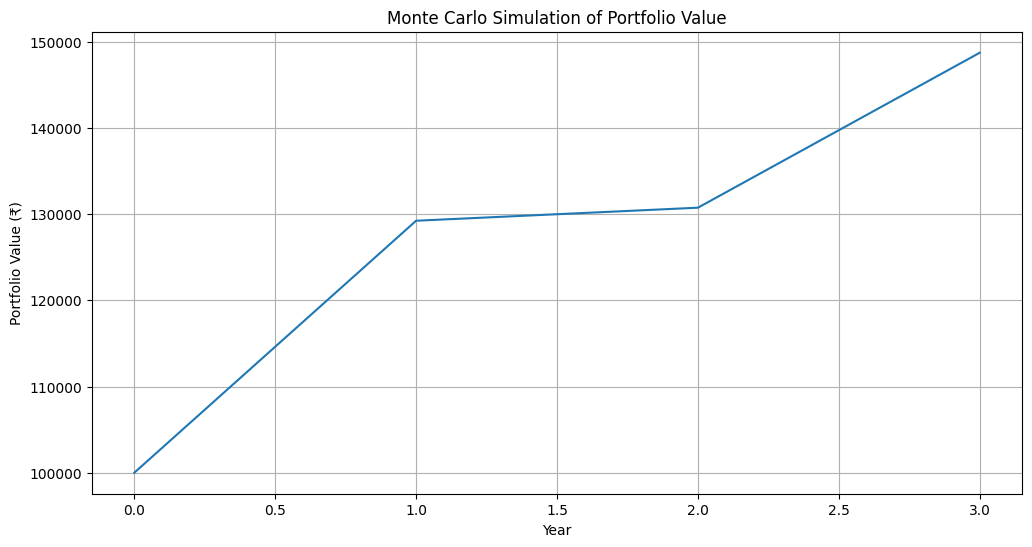

In [65]:
plt.figure(figsize=(12, 6))
plt.plot(portfolio_values)
plt.title("Monte Carlo Simulation of Portfolio Value")
plt.xlabel("Year")
plt.ylabel("Portfolio Value (₹)")
plt.grid(True)
plt.show()


```

Each line represents one possible investment outcome.

---


# Step 6: Analyze Final Outcomes

In [66]:

final_values = portfolio_values[-1]

print(f"Mean Final Value: ₹{final_values.mean():,.2f}")
print(f"Median Final Value: ₹{final_values.median() if hasattr(final_values, 'median') else np.median(final_values):,.2f}")
print(f"Best Case: ₹{final_values.max():,.2f}")
print(f"Worst Case: ₹{final_values.min():,.2f}")


Mean Final Value: ₹148,734.92
Median Final Value: ₹148,734.92
Best Case: ₹148,734.92
Worst Case: ₹148,734.92


In [67]:
# A simpler and more standard version:

print(f"Mean Final Value: ₹{np.mean(final_values):,.2f}")
print(f"Median Final Value: ₹{np.median(final_values):,.2f}")
print(f"Best Case: ₹{np.max(final_values):,.2f}")
print(f"Worst Case: ₹{np.min(final_values):,.2f}")


Mean Final Value: ₹148,734.92
Median Final Value: ₹148,734.92
Best Case: ₹148,734.92
Worst Case: ₹148,734.92


# Step 7: Probability of Losing Money

In [68]:
probability_of_loss = np.mean(final_values < initial_investment)

print(f"Probability of Loss: {probability_of_loss:.2%}")


Probability of Loss: 0.00%


In [69]:
# Step 8: 5th and 95th Percentiles

p5 = np.percentile(final_values, 5)
p95 = np.percentile(final_values, 95)

print(f"5th Percentile: ₹{p5:,.2f}")
print(f"95th Percentile: ₹{p95:,.2f}")


5th Percentile: ₹148,734.92
95th Percentile: ₹148,734.92


```

Interpretation:

* 5% of simulations end below this value.
* 95% of simulations end below this value.



# Now increase the number of years to 10 and simulations to 1000


# Fun Classroom Ideas

Ask students:

1. What happens if volatility increases to 40%?
2. What if expected return falls to 8%?
3. What if investment horizon increases to 30 years?
4. Which is more important: return or volatility?

---